In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/house-prices-advanced-regression-techniques/sample_submission.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/data_description.txt
/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv


In [2]:
import pandas as pd

# Đường dẫn dữ liệu trên Kaggle
data_path = "/kaggle/input/competitions/house-prices-advanced-regression-techniques/"

# Đọc dữ liệu
train = pd.read_csv(data_path + "train.csv")
test = pd.read_csv(data_path + "test.csv")

# Xem số dòng và số cột
print("Train:", train.shape)
print("Test:", test.shape)

# Xem 5 dòng đầu của tập train
display(train.head())

Train: (1460, 81)
Test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


#### kiểm tra cấu trúc và dữ liệu thiếu

In [3]:
# Kiểm tra số dòng, số cột
print("Train:", train.shape)
print("Test:", test.shape)

# Xem kiểu dữ liệu và số giá trị không thiếu của từng cột
train.info()

# Đếm giá trị thiếu và sắp xếp từ nhiều đến ít
missing = train.isna().sum().sort_values(ascending=False)

# Chỉ hiển thị những cột có dữ liệu thiếu
print("\nCác cột có dữ liệu thiếu:")
print(missing[missing > 0])

Train: (1460, 81)
Test: (1459, 80)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    14

In [4]:
#### Khám phá giá nhà - biến cần dự đoán

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


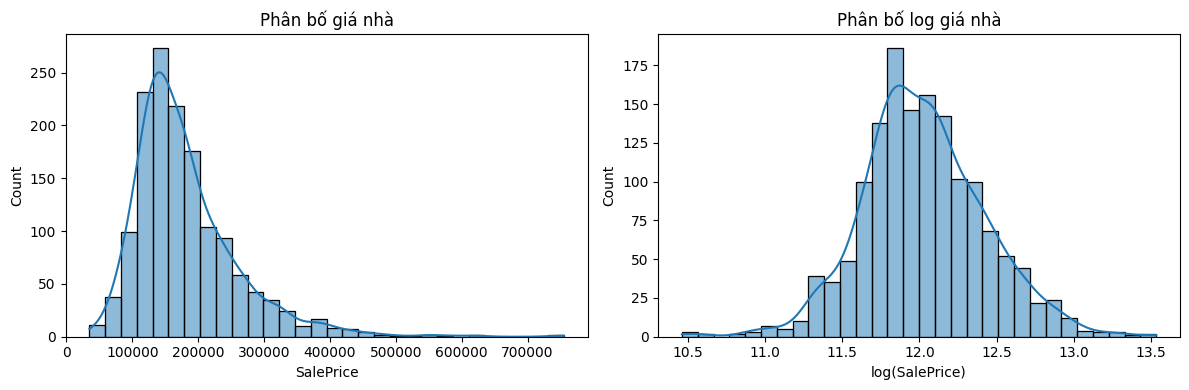

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thống kê giá nhà
print(train["SalePrice"].describe())

# So sánh phân bố giá gốc và log giá
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    train["SalePrice"],
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Phân bố giá nhà")
axes[0].set_xlabel("SalePrice")

sns.histplot(
    np.log(train["SalePrice"]),
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Phân bố log giá nhà")
axes[1].set_xlabel("log(SalePrice)")

plt.tight_layout()
plt.show()

#### Xem tương quan giữa các cột số và giá nhà

In [6]:
# Chọn các cột có kiểu dữ liệu số
numeric_data = train.select_dtypes(include="number")

# Tính tương quan với giá nhà
correlation = numeric_data.corr()["SalePrice"]

# Bỏ chính SalePrice và mã định danh Id
correlation = correlation.drop(["SalePrice", "Id"])

# Sắp xếp theo độ mạnh của tương quan, kể cả tương quan âm
top_features = correlation.abs().sort_values(ascending=False).head(10)

# Hiển thị hệ số tương quan gốc để giữ dấu âm/dương
print(correlation.loc[top_features.index])

OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64


#### Vẽ để quan sát quan hệ và các điểm bất thường

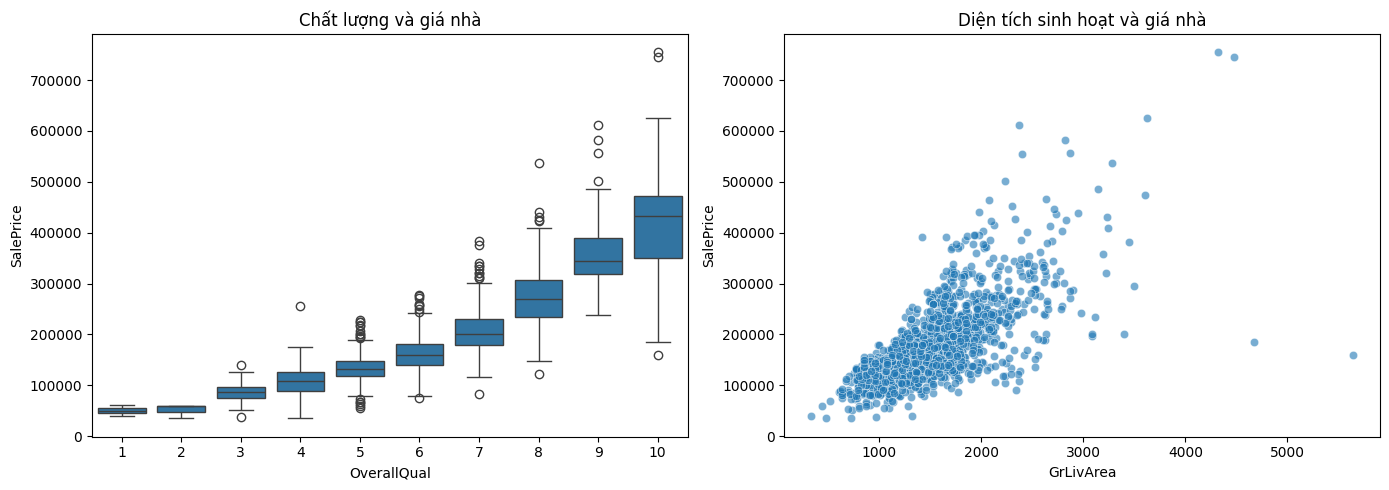

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Giá nhà theo từng mức chất lượng
sns.boxplot(
    data=train,
    x="OverallQual",
    y="SalePrice",
    ax=axes[0]
)
axes[0].set_title("Chất lượng và giá nhà")

# Giá nhà theo diện tích sinh hoạt
sns.scatterplot(
    data=train,
    x="GrLivArea",
    y="SalePrice",
    ax=axes[1],
    alpha=0.6
)
axes[1].set_title("Diện tích sinh hoạt và giá nhà")

plt.tight_layout()
plt.show()

In [8]:
# Kiểm tra các căn nhà có diện tích sinh hoạt lớn nhất
display(
    train.nlargest(5, "GrLivArea")[
        ["Id", "GrLivArea", "OverallQual", "SalePrice"]
    ]
)

,Id,GrLivArea,OverallQual,SalePrice
1298,1299,5642,10,160000
523,524,4676,10,184750
1182,1183,4476,10,745000
691,692,4316,10,755000
1169,1170,3627,10,625000


#### Tách mô hình thành Train/Validation

In [9]:
from sklearn.model_selection import train_test_split

# Đầu vào: các đặc điểm của căn nhà
# Bỏ Id vì đây là mã định danh
X = train.drop(columns=["Id", "SalePrice"])

# Đầu ra: log giá nhà
y = np.log(train["SalePrice"])

# Giữ riêng dữ liệu để dự đoán và nộp Kaggle
X_kaggle_test = test.drop(columns=["Id"])

# Chia 80% để học, 20% để đánh giá
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)
print("X_kaggle_test:", X_kaggle_test.shape)

X_train: (1168, 79)
X_valid: (292, 79)
y_train: (1168,)
y_valid: (292,)
X_kaggle_test: (1459, 79)


#### Xử lý dữ liệu thiếu

In [10]:
from sklearn.impute import SimpleImputer

# Copy để giữ nguyên dữ liệu trước xử lý
X_train_clean = X_train.copy()
X_valid_clean = X_valid.copy()
X_test_clean = X_kaggle_test.copy()

# Phân biệt cột số và cột phân loại
numeric_cols = X_train.select_dtypes(include="number").columns
categorical_cols = X_train.select_dtypes(exclude="number").columns

# Điền thiếu cho cột số
numeric_imputer = SimpleImputer(strategy="median")

X_train_clean[numeric_cols] = numeric_imputer.fit_transform(
    X_train[numeric_cols]
)

X_valid_clean[numeric_cols] = numeric_imputer.transform(
    X_valid[numeric_cols]
)

X_test_clean[numeric_cols] = numeric_imputer.transform(
    X_kaggle_test[numeric_cols]
)

# Điền thiếu cho cột chữ
X_train_clean[categorical_cols] = (
    X_train[categorical_cols].fillna("Missing")
)

X_valid_clean[categorical_cols] = (
    X_valid[categorical_cols].fillna("Missing")
)

X_test_clean[categorical_cols] = (
    X_kaggle_test[categorical_cols].fillna("Missing")
)

# Kiểm tra số ô còn thiếu
print("Train còn thiếu:", X_train_clean.isna().sum().sum())
print("Valid còn thiếu:", X_valid_clean.isna().sum().sum())
print("Test còn thiếu:", X_test_clean.isna().sum().sum())

Train còn thiếu: 0
Valid còn thiếu: 0
Test còn thiếu: 0


#### Chuyển cột phân loại thành số bằng One-hot Encoding

In [11]:
from sklearn.preprocessing import OneHotEncoder

# MSSubClass là mã loại nhà, nên xử lý như cột phân loại
for df in [X_train_clean, X_valid_clean, X_test_clean]:
    df["MSSubClass"] = df["MSSubClass"].astype(str)

# Cập nhật danh sách cột số và cột phân loại
numeric_cols = X_train_clean.select_dtypes(include="number").columns
categorical_cols = X_train_clean.select_dtypes(exclude="number").columns

# Tạo bộ mã hóa
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Chỉ học các nhóm giá trị từ train
train_cat = encoder.fit_transform(X_train_clean[categorical_cols])

# Áp dụng cách mã hóa đã học cho valid và test
valid_cat = encoder.transform(X_valid_clean[categorical_cols])
test_cat = encoder.transform(X_test_clean[categorical_cols])

# Lấy tên các cột sau mã hóa
encoded_cols = encoder.get_feature_names_out(categorical_cols)

In [12]:
def combine_features(df, encoded_data):
    # Chuyển kết quả mã hóa thành bảng, giữ đúng index
    encoded_df = pd.DataFrame(
        encoded_data,
        columns=encoded_cols,
        index=df.index
    )

    # Ghép cột số với cột đã mã hóa
    return pd.concat(
        [df[numeric_cols], encoded_df],
        axis=1
    )


X_train_encoded = combine_features(X_train_clean, train_cat)
X_valid_encoded = combine_features(X_valid_clean, valid_cat)
X_test_encoded = combine_features(X_test_clean, test_cat)

print("Train sau mã hóa:", X_train_encoded.shape)
print("Valid sau mã hóa:", X_valid_encoded.shape)
print("Test sau mã hóa:", X_test_encoded.shape)

Train sau mã hóa: (1168, 315)
Valid sau mã hóa: (292, 315)
Test sau mã hóa: (1459, 315)


#### Chuẩn hóa các cột số

In [13]:
from sklearn.preprocessing import StandardScaler

# Copy dữ liệu sau mã hóa
X_train_scaled = X_train_encoded.copy()
X_valid_scaled = X_valid_encoded.copy()
X_test_scaled = X_test_encoded.copy()

# Tạo bộ chuẩn hóa
scaler = StandardScaler()

# Chỉ học trung bình và độ lệch chuẩn từ train
X_train_scaled[numeric_cols] = scaler.fit_transform(
    X_train_encoded[numeric_cols]
)

# Áp dụng cùng thông số cho valid và test
X_valid_scaled[numeric_cols] = scaler.transform(
    X_valid_encoded[numeric_cols]
)

X_test_scaled[numeric_cols] = scaler.transform(
    X_test_encoded[numeric_cols]
)

# Xem thử các cột số sau chuẩn hóa
display(X_train_scaled[numeric_cols].head())

,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,...,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold
254,-0.012468,-0.212896,-0.820445,0.372217,-0.455469,-1.346063,-0.597889,1.037269,-0.285504,-0.400282,...,-0.863837,1.188402,-0.714352,-0.351921,-0.121008,-0.275838,-0.070993,-0.09274,-0.133417,1.650065
1066,-0.502357,-0.265245,-0.088934,1.268609,0.718609,0.439214,-0.597889,-0.971996,-0.285504,0.511920,...,-0.456264,-0.740157,-0.138015,-0.351921,-0.121008,-0.275838,-0.070993,-0.09274,-0.508010,0.893677
638,-0.146074,-0.177841,-0.820445,1.268609,-1.988293,-1.683818,-0.597889,-0.971996,-0.285504,0.505196,...,-2.257169,1.790113,-0.714352,2.290826,-0.121008,-0.275838,-0.070993,-0.09274,-0.508010,0.137290
799,-0.457822,-0.324474,-0.820445,1.268609,-1.107734,-1.683818,0.861522,0.267995,-0.285504,-0.915776,...,-1.119755,-0.740157,-0.714352,3.902257,-0.121008,-0.275838,-0.070993,-0.09274,-0.133417,-0.619098
380,-0.903175,-0.529035,-0.820445,0.372217,-1.531707,-1.683818,-0.597889,-0.496920,-0.285504,0.532091,...,-0.797488,-0.740157,-0.714352,3.547742,-0.121008,-0.275838,-0.070993,-0.09274,-0.508010,1.650065


#### Tạo baseline - mốc để so sánh

In [14]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error

# Tạo mô hình dự đoán trung bình
baseline = DummyRegressor(strategy="mean")

# Học trung bình log giá từ tập train
baseline.fit(X_train_scaled, y_train)

# Dự đoán trên validation
pred_baseline = baseline.predict(X_valid_scaled)

# Tính RMSE trên thang log
baseline_rmse = np.sqrt(
    mean_squared_error(y_valid, pred_baseline)
)

print("Baseline Valid Log-RMSE:", baseline_rmse)

Baseline Valid Log-RMSE: 0.43324686081152136


#### Huấn luyện Ridge Regression

In [15]:
from sklearn.linear_model import Ridge

# Tạo mô hình Ridge
ridge = Ridge(alpha=10)

# Huấn luyện trên tập train
ridge.fit(X_train_scaled, y_train)

# Dự đoán trên train và validation
pred_train_ridge = ridge.predict(X_train_scaled)
pred_valid_ridge = ridge.predict(X_valid_scaled)

# Tính sai số trên thang log
ridge_train_rmse = np.sqrt(
    mean_squared_error(y_train, pred_train_ridge)
)

ridge_valid_rmse = np.sqrt(
    mean_squared_error(y_valid, pred_valid_ridge)
)

print("Baseline Valid Log-RMSE:", baseline_rmse)
print("Ridge Train Log-RMSE:", ridge_train_rmse)
print("Ridge Valid Log-RMSE:", ridge_valid_rmse)

Baseline Valid Log-RMSE: 0.43324686081152136
Ridge Train Log-RMSE: 0.10801038026883568
Ridge Valid Log-RMSE: 0.13748265878439161


#### Xem những căn nhà dự đoán sai nhiều nhất

In [16]:
# Lấy thông tin gốc của các căn thuộc validation
errors = train.loc[
    X_valid.index,
    ["Id", "OverallQual", "GrLivArea", "SalePrice"]
].copy()

# Đổi dự đoán từ log về giá nhà
errors["PredictedPrice"] = np.exp(pred_valid_ridge)

# Sai số có dấu: dương là đoán cao, âm là đoán thấp
errors["Error"] = errors["PredictedPrice"] - errors["SalePrice"]

# Độ lớn sai số theo giá gốc
errors["AbsoluteError"] = errors["Error"].abs()

# Độ lớn sai số trên thang log
errors["AbsoluteLogError"] = np.abs(
    y_valid - pred_valid_ridge
)

# Xem 10 căn sai nhiều nhất trên thang log
display(
    errors.sort_values(
        "AbsoluteLogError",
        ascending=False
    ).head(10)
)

,Id,OverallQual,GrLivArea,SalePrice,PredictedPrice,Error,AbsoluteError,AbsoluteLogError
30,31,4,1317,40000,88611.841168,48611.841168,48611.841168,0.795386
916,917,2,480,35311,69121.469518,33810.469518,33810.469518,0.671671
812,813,5,1044,55993,103242.141119,47249.141119,47249.141119,0.611850
1432,1433,4,968,64500,102181.397530,37681.397530,37681.397530,0.460084
588,589,5,1473,143000,225025.984510,82025.984510,82025.984510,0.453371
628,629,5,2080,135000,206962.684700,71962.684700,71962.684700,0.427264
874,875,5,1131,66500,98101.302877,31601.302877,31601.302877,0.388799
1170,1171,6,1118,171000,121243.476953,-49756.523047,49756.523047,0.343863
898,899,9,2364,611657,435367.976495,-176289.023505,176289.023505,0.339980
774,775,8,1973,395000,289018.911967,-105981.088033,105981.088033,0.312394


#### Thử mức phạt alpha của Ridge

In [17]:
# Các mức phạt muốn thử
alphas = [0.1, 1, 10, 30, 100, 300]

ridge_results = []

for alpha in alphas:
    # Tạo và huấn luyện mô hình
    model = Ridge(alpha=alpha)
    model.fit(X_train_scaled, y_train)

    # Dự đoán
    train_pred = model.predict(X_train_scaled)
    valid_pred = model.predict(X_valid_scaled)

    # Tính sai số
    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_pred)
    )

    valid_rmse = np.sqrt(
        mean_squared_error(y_valid, valid_pred)
    )

    # Lưu kết quả của từng alpha
    ridge_results.append({
        "alpha": alpha,
        "Train Log-RMSE": train_rmse,
        "Valid Log-RMSE": valid_rmse
    })

# Sắp xếp theo sai số validation tăng dần
ridge_results_df = pd.DataFrame(ridge_results).sort_values(
    "Valid Log-RMSE"
)

display(ridge_results_df)

,alpha,Train Log-RMSE,Valid Log-RMSE
0,0.1,0.090386,0.130757
1,1.0,0.096506,0.133778
2,10.0,0.108010,0.137483
3,30.0,0.114413,0.138042
4,100.0,0.123540,0.140025
5,300.0,0.133820,0.145785


#### Kiểm tra Ridge bằng K-Fold

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score

# Dùng đầu vào chưa điền thiếu, mã hóa hoặc chuẩn hóa
X_cv = X.copy()

# Mã loại nhà được xem là cột phân loại
X_cv["MSSubClass"] = X_cv["MSSubClass"].astype(str)

num_cols_cv = X_cv.select_dtypes(include="number").columns
cat_cols_cv = X_cv.select_dtypes(exclude="number").columns

# Xử lý cột số
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Xử lý cột phân loại
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Kết hợp hai nhánh xử lý
preprocessor_cv = ColumnTransformer([
    ("numeric", numeric_pipeline, num_cols_cv),
    ("categorical", categorical_pipeline, cat_cols_cv)
])

# Ghép tiền xử lý và mô hình thành một quy trình
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor_cv),
    ("model", Ridge(alpha=0.1))
])

# Chia 5 fold
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Đánh giá trên từng fold
scores = cross_val_score(
    ridge_pipeline,
    X_cv,
    y,
    cv=kf,
    scoring="neg_mean_squared_error"
)

# Đổi từ MSE âm thành RMSE
cv_rmse = np.sqrt(-scores)

print("Log-RMSE từng fold:", cv_rmse)
print("CV trung bình:", cv_rmse.mean())
print("CV độ lệch chuẩn:", cv_rmse.std())

Log-RMSE từng fold: [0.13075745 0.12470093 0.23627663 0.14639264 0.11484733]
CV trung bình: 0.15059499336070828
CV độ lệch chuẩn: 0.044047539180675194


#### Kiểm tra những căn sai nhiều nhất ở fold 3

In [19]:
from sklearn.base import clone

# Lấy vị trí các dòng train và validation của fold 3
splits = list(kf.split(X_cv))
train_idx, valid_idx = splits[2]

# Tạo bản mô hình mới và huấn luyện riêng cho fold 3
fold3_model = clone(ridge_pipeline)

fold3_model.fit(
    X_cv.iloc[train_idx],
    y.iloc[train_idx]
)

# Dự đoán log giá của validation fold 3
fold3_pred = fold3_model.predict(
    X_cv.iloc[valid_idx]
)

# Lấy thông tin gốc của các căn nhà trong fold này
fold3_errors = train.loc[
    X_cv.iloc[valid_idx].index,
    ["Id", "OverallQual", "GrLivArea", "SalePrice"]
].copy()

# Đổi dự đoán về giá gốc
fold3_errors["PredictedPrice"] = np.exp(fold3_pred)

# Tính độ lớn sai số log
fold3_errors["AbsoluteLogError"] = np.abs(
    y.iloc[valid_idx].to_numpy() - fold3_pred
)

# Xem 10 căn sai nhiều nhất
display(
    fold3_errors.sort_values(
        "AbsoluteLogError",
        ascending=False
    ).head(10)
)

,Id,OverallQual,GrLivArea,SalePrice,PredictedPrice,AbsoluteLogError
1298,1299,10,5642,160000,3.339664e+06,3.038452
523,524,10,4676,184750,9.466122e+05,1.633886
1324,1325,8,1795,147000,2.803671e+05,0.645667
1270,1271,7,1524,260000,1.459542e+05,0.577389
533,534,1,334,39300,6.618028e+04,0.521158
970,971,4,1192,135000,8.217024e+04,0.496482
1453,1454,5,1140,84500,1.308192e+05,0.437065
1443,1444,6,952,121000,7.941949e+04,0.421047
557,558,4,1336,108000,7.175427e+04,0.408884
1000,1001,3,944,82000,5.541678e+04,0.391837


#### So sánh alpha trên cùng 5 fold

In [20]:
alphas = [0.1, 1, 10, 30, 100, 300]

cv_results = []

for alpha in alphas:
    # Tạo pipeline mới với alpha đang thử
    model = clone(ridge_pipeline)
    model.set_params(model__alpha=alpha)

    # Đánh giá trên cùng cách chia 5 fold
    scores = cross_val_score(
        model,
        X_cv,
        y,
        cv=kf,
        scoring="neg_mean_squared_error"
    )

    fold_rmse = np.sqrt(-scores)

    # Lưu kết quả
    cv_results.append({
        "alpha": alpha,
        "CV Mean": fold_rmse.mean(),
        "CV Std": fold_rmse.std(),
        "Fold 3": fold_rmse[2]
    })

cv_results_df = pd.DataFrame(cv_results).sort_values("CV Mean")

display(cv_results_df)

,alpha,CV Mean,CV Std,Fold 3
3,30.0,0.145321,0.040576,0.224932
2,10.0,0.145776,0.039571,0.223486
4,100.0,0.146213,0.040167,0.224825
1,1.0,0.147823,0.040689,0.228276
5,300.0,0.149258,0.036797,0.220523
0,0.1,0.150595,0.044048,0.236277


In [21]:
from sklearn.ensemble import RandomForestRegressor

# Giữ quy trình tiền xử lý và thay mô hình
rf_pipeline = clone(ridge_pipeline)

rf_pipeline.set_params(
    model=RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
)

# Đánh giá trên cùng 5 fold
rf_scores = cross_val_score(
    rf_pipeline,
    X_cv,
    y,
    cv=kf,
    scoring="neg_mean_squared_error",
    n_jobs=1
)

rf_cv_rmse = np.sqrt(-rf_scores)

print("Random Forest Log-RMSE từng fold:", rf_cv_rmse)
print("Random Forest CV trung bình:", rf_cv_rmse.mean())
print("Random Forest CV độ lệch chuẩn:", rf_cv_rmse.std())

Random Forest Log-RMSE từng fold: [0.14740203 0.1281495  0.17689426 0.1488381  0.12228753]
Random Forest CV trung bình: 0.14471428333691455
Random Forest CV độ lệch chuẩn: 0.019168369207086925


In [22]:
X_train = X_train.copy()
X_valid = X_valid.copy()

X_train["MSSubClass"] = X_train["MSSubClass"].astype(str)
X_valid["MSSubClass"] = X_valid["MSSubClass"].astype(str)

In [23]:
# Huấn luyện toàn bộ pipeline bằng dữ liệu train chưa xử lý
rf_pipeline.fit(X_train, y_train)

# Dự đoán trên train và validation
rf_train_pred = rf_pipeline.predict(X_train)
rf_valid_pred = rf_pipeline.predict(X_valid)

# Tính sai số trên thang log
rf_train_rmse = np.sqrt(
    mean_squared_error(y_train, rf_train_pred)
)

rf_valid_rmse = np.sqrt(
    mean_squared_error(y_valid, rf_valid_pred)
)

print("Random Forest Train Log-RMSE:", rf_train_rmse)
print("Random Forest Valid Log-RMSE:", rf_valid_rmse)

Random Forest Train Log-RMSE: 0.06433714172977706
Random Forest Valid Log-RMSE: 0.14526096696591437


In [24]:
leaf_values = [1, 2, 4, 8]

rf_results = []

for leaf in leaf_values:
    # Tạo pipeline mới và thay số mẫu tối thiểu ở mỗi lá
    model = clone(rf_pipeline)
    model.set_params(model__min_samples_leaf=leaf)

    # Đánh giá trên cùng 5 fold
    scores = cross_val_score(
        model,
        X_cv,
        y,
        cv=kf,
        scoring="neg_mean_squared_error",
        n_jobs=1
    )

    fold_rmse = np.sqrt(-scores)

    rf_results.append({
        "min_samples_leaf": leaf,
        "CV Mean": fold_rmse.mean(),
        "CV Std": fold_rmse.std()
    })

rf_results_df = pd.DataFrame(rf_results).sort_values("CV Mean")
display(rf_results_df)

,min_samples_leaf,CV Mean,CV Std
0,1,0.144305,0.019079
1,2,0.144714,0.019168
2,4,0.145906,0.018549
3,8,0.150960,0.017438


#### Tạo đặc trưng tổng diện tích

In [25]:
# Copy dữ liệu chưa tiền xử lý
X_v2 = X_cv.copy()

# Tổng diện tích tầng hầm và hai tầng trên mặt đất
X_v2["TotalSF"] = (
    X_v2["TotalBsmtSF"]
    + X_v2["1stFlrSF"]
    + X_v2["2ndFlrSF"]
)

# Cập nhật danh sách cột số để pipeline nhận cột mới
num_cols_v2 = X_v2.select_dtypes(include="number").columns

# Tạo pipeline riêng cho lần thử này
rf_v2 = clone(rf_pipeline)

rf_v2.set_params(
    model__min_samples_leaf=1,
    preprocessor__numeric__scaler=StandardScaler()
)

# Cập nhật các cột đưa vào bộ tiền xử lý
rf_v2.named_steps["preprocessor"].transformers = [
    ("numeric", clone(numeric_pipeline), num_cols_v2),
    ("categorical", clone(categorical_pipeline), cat_cols_cv)
]

# Đánh giá trên cùng 5 fold
scores_v2 = cross_val_score(
    rf_v2,
    X_v2,
    y,
    cv=kf,
    scoring="neg_mean_squared_error",
    n_jobs=1
)

rmse_v2 = np.sqrt(-scores_v2)

print("RF trước khi thêm TotalSF:", 0.144305)
print("RF thêm TotalSF - CV Mean:", rmse_v2.mean())
print("RF thêm TotalSF - CV Std:", rmse_v2.std())

RF trước khi thêm TotalSF: 0.144305
RF thêm TotalSF - CV Mean: 0.14288775935001855
RF thêm TotalSF - CV Std: 0.017818898663672703


In [26]:
# Giữ TotalSF và thêm tuổi nhà
X_v3 = X_v2.copy()

X_v3["HouseAge"] = (
    X_v3["YrSold"] - X_v3["YearBuilt"]
).clip(lower=0)

# Cập nhật danh sách cột số
num_cols_v3 = X_v3.select_dtypes(include="number").columns

# Tạo bộ tiền xử lý nhận cả đặc trưng mới
preprocessor_v3 = ColumnTransformer([
    ("numeric", clone(numeric_pipeline), num_cols_v3),
    ("categorical", clone(categorical_pipeline), cat_cols_cv)
])

# Giữ nguyên cấu hình Random Forest để so sánh
rf_v3 = Pipeline([
    ("preprocessor", preprocessor_v3),
    ("model", RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

# Đánh giá trên cùng 5 fold
scores_v3 = cross_val_score(
    rf_v3,
    X_v3,
    y,
    cv=kf,
    scoring="neg_mean_squared_error",
    n_jobs=1
)

rmse_v3 = np.sqrt(-scores_v3)

print("RF + TotalSF - CV Mean:", rmse_v2.mean())
print("RF + TotalSF + HouseAge - CV Mean:", rmse_v3.mean())
print("RF + TotalSF + HouseAge - CV Std:", rmse_v3.std())

RF + TotalSF - CV Mean: 0.14288775935001855
RF + TotalSF + HouseAge - CV Mean: 0.14283499204764527
RF + TotalSF + HouseAge - CV Std: 0.017951873427270667


In [27]:
# Dùng bản có TotalSF, chưa thêm HouseAge
X_bath = X_v2.copy()

# Tổng số phòng tắm quy đổi
X_bath["TotalBath"] = (
    X_bath["FullBath"]
    + 0.5 * X_bath["HalfBath"]
    + X_bath["BsmtFullBath"]
    + 0.5 * X_bath["BsmtHalfBath"]
)

# Cập nhật danh sách cột số
num_cols_bath = X_bath.select_dtypes(include="number").columns

# Tạo bộ tiền xử lý nhận cột mới
preprocessor_bath = ColumnTransformer([
    ("numeric", clone(numeric_pipeline), num_cols_bath),
    ("categorical", clone(categorical_pipeline), cat_cols_cv)
])

# Giữ nguyên cấu hình mô hình
rf_bath = Pipeline([
    ("preprocessor", preprocessor_bath),
    ("model", clone(rf_v2.named_steps["model"]))
])

# Đánh giá bằng cùng 5 fold
scores_bath = cross_val_score(
    rf_bath,
    X_bath,
    y,
    cv=kf,
    scoring="neg_mean_squared_error",
    n_jobs=1
)

rmse_bath = np.sqrt(-scores_bath)

print("RF + TotalSF - CV Mean:", rmse_v2.mean())
print("RF + TotalSF + TotalBath - CV Mean:", rmse_bath.mean())
print("RF + TotalSF + TotalBath - CV Std:", rmse_bath.std())

RF + TotalSF - CV Mean: 0.14288775935001855
RF + TotalSF + TotalBath - CV Mean: 0.14257486618561901
RF + TotalSF + TotalBath - CV Std: 0.018208090627041432


In [28]:
max_features_values = [0.5, 0.8, 1.0]

feature_results = []

for value in max_features_values:
    # Giữ dữ liệu và các tham số khác như cũ
    model = clone(rf_bath)
    model.set_params(model__max_features=value)

    # Đánh giá trên cùng 5 fold
    scores = cross_val_score(
        model,
        X_bath,
        y,
        cv=kf,
        scoring="neg_mean_squared_error",
        n_jobs=1
    )

    fold_rmse = np.sqrt(-scores)

    feature_results.append({
        "max_features": value,
        "CV Mean": fold_rmse.mean(),
        "CV Std": fold_rmse.std()
    })

feature_results_df = pd.DataFrame(feature_results).sort_values(
    "CV Mean"
)

display(feature_results_df)

,max_features,CV Mean,CV Std
0,0.5,0.137943,0.017883
1,0.8,0.140209,0.017491
2,1.0,0.142575,0.018208


In [29]:
depth_values = [10, 20, None]

depth_results = []

for depth in depth_values:
    # Giữ cấu hình tốt nhất và thay độ sâu tối đa
    model = clone(rf_bath)

    model.set_params(
        model__max_features=0.5,
        model__max_depth=depth
    )

    # Đánh giá trên cùng 5 fold
    scores = cross_val_score(
        model,
        X_bath,
        y,
        cv=kf,
        scoring="neg_mean_squared_error",
        n_jobs=1
    )

    fold_rmse = np.sqrt(-scores)

    depth_results.append({
        "max_depth": str(depth),
        "CV Mean": fold_rmse.mean(),
        "CV Std": fold_rmse.std()
    })

depth_results_df = pd.DataFrame(depth_results).sort_values(
    "CV Mean"
)

display(depth_results_df)

,max_depth,CV Mean,CV Std
2,None,0.137943,0.017883
1,20,0.137953,0.017695
0,10,0.139285,0.017147


In [30]:
# Tạo mô hình cuối với cấu hình đã chọn
final_rf = clone(rf_bath)

final_rf.set_params(
    model__max_features=0.5,
    model__max_depth=None
)

# X_bath gồm toàn bộ dữ liệu có nhãn
# và đã có TotalSF, TotalBath
final_rf.fit(X_bath, y)

print("Đã huấn luyện mô hình cuối.")
print("Số dòng và cột đầu vào:", X_bath.shape)

Đã huấn luyện mô hình cuối.
Số dòng và cột đầu vào: (1460, 81)


In [31]:
# Dùng dữ liệu test gốc, chưa điền thiếu hay mã hóa
X_submit = test.drop(columns=["Id"]).copy()

# Chuyển mã loại nhà thành cột phân loại
X_submit["MSSubClass"] = X_submit["MSSubClass"].astype(str)

# Tạo đặc trưng giống dữ liệu huấn luyện
X_submit["TotalSF"] = (
    X_submit["TotalBsmtSF"]
    + X_submit["1stFlrSF"]
    + X_submit["2ndFlrSF"]
)

X_submit["TotalBath"] = (
    X_submit["FullBath"]
    + 0.5 * X_submit["HalfBath"]
    + X_submit["BsmtFullBath"]
    + 0.5 * X_submit["BsmtHalfBath"]
)

# Giữ cùng thứ tự cột với tập huấn luyện
X_submit = X_submit[X_bath.columns]

print("Dữ liệu để nộp:", X_submit.shape)

Dữ liệu để nộp: (1459, 81)


In [32]:
# Dự đoán log giá nhà
pred_test_log = final_rf.predict(X_submit)

# Đổi về giá gốc vì lúc huấn luyện dùng np.log(SalePrice)
pred_test_price = np.exp(pred_test_log)

# Tạo bảng nộp, giữ đúng Id và thứ tự của test
submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": pred_test_price
})

# Kiểm tra kết quả
display(submission.head())

print("Kích thước:", submission.shape)
print("Số ô thiếu:", submission.isna().sum().sum())
print("Tất cả giá hữu hạn:", np.isfinite(pred_test_price).all())
print("Tất cả giá dương:", (submission["SalePrice"] > 0).all())

# Lưu file CSV
submission.to_csv(
    "/kaggle/working/submission_rf_v1.csv",
    index=False
)

print("Đã tạo submission_rf_v1.csv")

,Id,SalePrice
0,1461,124981.791084
1,1462,157636.969766
2,1463,178294.525772
3,1464,183520.947503
4,1465,195353.823708


Kích thước: (1459, 2)
Số ô thiếu: 0
Tất cả giá hữu hạn: True
Tất cả giá dương: True
Đã tạo submission_rf_v1.csv


#### Huấn luyện và đánh giá V2 bằng CV

In [33]:
from sklearn.ensemble import GradientBoostingRegressor

# Copy pipeline V1 để giữ nguyên tiền xử lý
gb_v2 = clone(final_rf)

# Thay Random Forest bằng Gradient Boosting
gb_v2.set_params(
    model=GradientBoostingRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=3,
        min_samples_leaf=5,
        loss="squared_error",
        random_state=42
    )
)

# Đánh giá trên cùng dữ liệu và 5 fold của V1
gb_scores = cross_val_score(
    gb_v2,
    X_bath,
    y,
    cv=kf,
    scoring="neg_mean_squared_error",
    n_jobs=1
)

gb_cv_rmse = np.sqrt(-gb_scores)

print("V2 Log-RMSE từng fold:", gb_cv_rmse)
print("V2 CV trung bình:", gb_cv_rmse.mean())
print("V2 CV độ lệch chuẩn:", gb_cv_rmse.std())

print("\nV1 Random Forest CV:", 0.137943)

V2 Log-RMSE từng fold: [0.13771537 0.1160635  0.16973446 0.13014845 0.11571855]
V2 CV trung bình: 0.13387606621226872
V2 CV độ lệch chuẩn: 0.019806276317630267

V1 Random Forest CV: 0.137943


In [34]:
# Lấy dữ liệu có đặc trưng mới theo lần chia ban đầu
X_train_v2 = X_bath.loc[X_train.index]
X_valid_v2 = X_bath.loc[X_valid.index]

# Tạo mô hình riêng để kiểm tra
gb_check = clone(gb_v2)

# Pipeline tự học tiền xử lý từ train
gb_check.fit(X_train_v2, y_train)

# Dự đoán trên train và validation
gb_train_pred = gb_check.predict(X_train_v2)
gb_valid_pred = gb_check.predict(X_valid_v2)

# Tính sai số trên thang log
gb_train_rmse = np.sqrt(
    mean_squared_error(y_train, gb_train_pred)
)

gb_valid_rmse = np.sqrt(
    mean_squared_error(y_valid, gb_valid_pred)
)

print("V2 Train Log-RMSE:", gb_train_rmse)
print("V2 Valid Log-RMSE:", gb_valid_rmse)

V2 Train Log-RMSE: 0.0712894903440999
V2 Valid Log-RMSE: 0.13771536704764403


In [35]:
depth_values = [1, 2, 3]

gb_depth_results = []

for depth in depth_values:
    # Tạo pipeline mới và thay độ sâu cây
    model = clone(gb_v2)
    model.set_params(model__max_depth=depth)

    # Đánh giá trên cùng 5 fold
    scores = cross_val_score(
        model,
        X_bath,
        y,
        cv=kf,
        scoring="neg_mean_squared_error",
        n_jobs=1
    )

    fold_rmse = np.sqrt(-scores)

    gb_depth_results.append({
        "max_depth": depth,
        "CV Mean": fold_rmse.mean(),
        "CV Std": fold_rmse.std()
    })

gb_depth_df = pd.DataFrame(gb_depth_results).sort_values("CV Mean")

display(gb_depth_df)

,max_depth,CV Mean,CV Std
1,2,0.133065,0.018511
2,3,0.133876,0.019806
0,1,0.140661,0.011777


In [36]:
tree_values = [300, 500, 800, 1200]

gb_tree_results = []

for n_trees in tree_values:
    model = clone(gb_v2)

    model.set_params(
        model__max_depth=2,
        model__n_estimators=n_trees
    )

    scores = cross_val_score(
        model,
        X_bath,
        y,
        cv=kf,
        scoring="neg_mean_squared_error",
        n_jobs=1
    )

    fold_rmse = np.sqrt(-scores)

    gb_tree_results.append({
        "n_estimators": n_trees,
        "CV Mean": fold_rmse.mean(),
        "CV Std": fold_rmse.std()
    })

gb_tree_df = pd.DataFrame(gb_tree_results).sort_values("CV Mean")

display(gb_tree_df)

,n_estimators,CV Mean,CV Std
3,1200,0.131165,0.019691
2,800,0.131459,0.019242
1,500,0.133065,0.018511
0,300,0.136258,0.016257


In [37]:
# Tạo pipeline V2 với cấu hình đã chọn
final_gb_v2 = clone(gb_v2)

final_gb_v2.set_params(
    model__max_depth=2,
    model__n_estimators=1200
)

# Học trên toàn bộ 1.460 căn nhà có nhãn
final_gb_v2.fit(X_bath, y)

# Dự đoán log giá trên tập test đã tạo đặc trưng
pred_v2_log = final_gb_v2.predict(X_submit)

# Đổi về giá gốc
pred_v2_price = np.exp(pred_v2_log)

# Tạo file nộp
submission_v2 = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": pred_v2_price
})

submission_v2.to_csv(
    "/kaggle/working/submission_gb_v2.csv",
    index=False
)

display(submission_v2.head())

print("Kích thước:", submission_v2.shape)
print("Số ô thiếu:", submission_v2.isna().sum().sum())
print("Giá hữu hạn và dương:",
      (np.isfinite(pred_v2_price) & (pred_v2_price > 0)).all())
print("Đã tạo submission_gb_v2.csv")

,Id,SalePrice
0,1461,117162.352824
1,1462,161363.230772
2,1463,181485.568612
3,1464,189127.494230
4,1465,188587.321261


Kích thước: (1459, 2)
Số ô thiếu: 0
Giá hữu hạn và dương: True
Đã tạo submission_gb_v2.csv


# V3

#### Tạo dự đoán OOF cho hai mô hình

In [38]:
from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_predict

In [39]:
from sklearn.model_selection import cross_val_predict

# Ridge dùng cùng đặc trưng TotalSF và TotalBath như V2
ridge_v3 = clone(final_gb_v2)

ridge_v3.set_params(
    model=Ridge(alpha=30)
)

# OOF của Ridge
oof_ridge = cross_val_predict(
    ridge_v3,
    X_bath,
    y,
    cv=kf,
    n_jobs=1
)

# OOF của Gradient Boosting V2
oof_gb = cross_val_predict(
    clone(final_gb_v2),
    X_bath,
    y,
    cv=kf,
    n_jobs=1
)

# Tính RMSE trên toàn bộ dự đoán OOF
ridge_oof_rmse = np.sqrt(
    mean_squared_error(y, oof_ridge)
)

gb_oof_rmse = np.sqrt(
    mean_squared_error(y, oof_gb)
)

print("Ridge OOF Log-RMSE:", ridge_oof_rmse)
print("Gradient Boosting OOF Log-RMSE:", gb_oof_rmse)

Ridge OOF Log-RMSE: 0.15115623603502926
Gradient Boosting OOF Log-RMSE: 0.13263439654452802


#### Thử tỷ trọng kết hợp dự đoán OOF

In [40]:
weights = [0, 0.1, 0.2, 0.3, 0.5]

blend_results = []

for weight in weights:
    # Kết hợp dự đoán trên thang log
    oof_blend = (
        weight * oof_ridge
        + (1 - weight) * oof_gb
    )

    blend_rmse = np.sqrt(
        mean_squared_error(y, oof_blend)
    )

    blend_results.append({
        "Ridge weight": weight,
        "GB weight": 1 - weight,
        "OOF Log-RMSE": blend_rmse
    })

blend_df = pd.DataFrame(blend_results).sort_values("OOF Log-RMSE")

display(blend_df)

,Ridge weight,GB weight,OOF Log-RMSE
1,0.1,0.9,0.132309
2,0.2,0.8,0.132496
0,0.0,1.0,0.132634
3,0.3,0.7,0.133195
4,0.5,0.5,0.136089


#### Huấn luyện 2 mô hình và xuất V3

In [41]:
# Tạo hai pipeline chưa huấn luyện
final_ridge_v3 = clone(ridge_v3)
final_gb_v3 = clone(final_gb_v2)

# Huấn luyện trên toàn bộ dữ liệu có nhãn
final_ridge_v3.fit(X_bath, y)
final_gb_v3.fit(X_bath, y)

# Dự đoán log giá trên Kaggle test
ridge_test_log = final_ridge_v3.predict(X_submit)
gb_test_log = final_gb_v3.predict(X_submit)

# Kết hợp trên thang log
blend_test_log = (
    0.1 * ridge_test_log
    + 0.9 * gb_test_log
)

# Đổi về giá gốc và tạo bảng nộp
submission_v3 = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": np.exp(blend_test_log)
})

# Kiểm tra trước khi lưu
print("Kích thước:", submission_v3.shape)
print("Số ô thiếu:", submission_v3.isna().sum().sum())
print(
    "Giá hữu hạn và dương:",
    (
        np.isfinite(submission_v3["SalePrice"])
        & (submission_v3["SalePrice"] > 0)
    ).all()
)

submission_v3.to_csv(
    "/kaggle/working/submission_blend_v3.csv",
    index=False
)

display(submission_v3.head())

Kích thước: (1459, 2)
Số ô thiếu: 0
Giá hữu hạn và dương: True


,Id,SalePrice
0,1461,116778.674015
1,1462,159983.203135
2,1463,180314.661726
3,1464,189733.461760
4,1465,189062.688221


# V4 — bước 1: thử hàm mất mát Huber cho Gradient Boosting

In [42]:
# Giữ cấu hình GB tốt nhất, chỉ thay hàm mất mát
gb_huber_v4 = clone(final_gb_v2)

gb_huber_v4.set_params(
    model__loss="huber",
    model__alpha=0.9
)

# Tạo dự đoán ngoài fold trên cùng 5 fold
oof_huber = cross_val_predict(
    gb_huber_v4,
    X_bath,
    y,
    cv=kf,
    n_jobs=1
)

huber_oof_rmse = np.sqrt(
    mean_squared_error(y, oof_huber)
)

print("GB squared_error OOF:", gb_oof_rmse)
print("GB Huber OOF:", huber_oof_rmse)

GB squared_error OOF: 0.13263439654452802
GB Huber OOF: 0.13094120752186528


#### thử tỷ trọng Ridge + GB Huber

In [43]:
weights = [0, 0.1, 0.2, 0.3]

huber_blend_results = []

for weight in weights:
    # Kết hợp các dự đoán ngoài fold trên thang log
    oof_blend_huber = (
        weight * oof_ridge
        + (1 - weight) * oof_huber
    )

    rmse = np.sqrt(
        mean_squared_error(y, oof_blend_huber)
    )

    huber_blend_results.append({
        "Ridge weight": weight,
        "Huber weight": 1 - weight,
        "OOF Log-RMSE": rmse
    })

huber_blend_df = pd.DataFrame(huber_blend_results).sort_values(
    "OOF Log-RMSE"
)

display(huber_blend_df)

print("V3 OOF:", np.sqrt(
    mean_squared_error(y, 0.1 * oof_ridge + 0.9 * oof_gb)
))

,Ridge weight,Huber weight,OOF Log-RMSE
1,0.1,0.9,0.130780
0,0.0,1.0,0.130941
2,0.2,0.8,0.131139
3,0.3,0.7,0.132013


V3 OOF: 0.13230863772652793


In [44]:
print(huber_blend_df.to_string(index=False))

 Ridge weight  Huber weight  OOF Log-RMSE
          0.1           0.9      0.130780
          0.0           1.0      0.130941
          0.2           0.8      0.131139
          0.3           0.7      0.132013


#### Huấn luyện và xuất file V4

In [45]:
# Tạo hai pipeline mới
final_ridge_v4 = clone(ridge_v3)
final_huber_v4 = clone(gb_huber_v4)

# Huấn luyện trên toàn bộ dữ liệu có nhãn
final_ridge_v4.fit(X_bath, y)
final_huber_v4.fit(X_bath, y)

# Dự đoán log giá nhà
ridge_v4_log = final_ridge_v4.predict(X_submit)
huber_v4_log = final_huber_v4.predict(X_submit)

# Kết hợp theo tỷ trọng đã chọn
blend_v4_log = (
    0.1 * ridge_v4_log
    + 0.9 * huber_v4_log
)

# Đổi về giá gốc
submission_v4 = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": np.exp(blend_v4_log)
})

# Kiểm tra đầu ra
print("Kích thước:", submission_v4.shape)
print("Số ô thiếu:", submission_v4.isna().sum().sum())
print(
    "Giá hữu hạn và dương:",
    (
        np.isfinite(submission_v4["SalePrice"])
        & (submission_v4["SalePrice"] > 0)
    ).all()
)

# Lưu riêng file V4
submission_v4.to_csv(
    "/kaggle/working/submission_huber_blend_v4.csv",
    index=False
)

display(submission_v4.head())

Kích thước: (1459, 2)
Số ô thiếu: 0
Giá hữu hạn và dương: True


,Id,SalePrice
0,1461,121729.972793
1,1462,163886.570320
2,1463,186220.316098
3,1464,190407.928027
4,1465,190696.330764


In [46]:
huber_alphas = [0.8, 0.9, 0.95]

huber_alpha_results = []

for alpha in huber_alphas:
    model = clone(gb_huber_v4)
    model.set_params(model__alpha=alpha)

    # Dự đoán ngoài fold của GB Huber
    oof_pred = cross_val_predict(
        model,
        X_bath,
        y,
        cv=kf,
        n_jobs=1
    )

    # Giữ tỷ trọng kết hợp như V4
    oof_blend = 0.1 * oof_ridge + 0.9 * oof_pred

    huber_alpha_results.append({
        "Huber alpha": alpha,
        "Blend OOF Log-RMSE": np.sqrt(
            mean_squared_error(y, oof_blend)
        )
    })

huber_alpha_df = pd.DataFrame(huber_alpha_results).sort_values(
    "Blend OOF Log-RMSE"
)

display(huber_alpha_df)

,Huber alpha,Blend OOF Log-RMSE
1,0.90,0.130780
2,0.95,0.131115
0,0.80,0.131657


In [47]:
subsample_values = [0.8, 1.0]
subsample_results = []

for value in subsample_values:
    model = clone(gb_huber_v4)

    model.set_params(
        model__alpha=0.9,
        model__subsample=value
    )

    # Tạo dự đoán ngoài fold
    oof_pred = cross_val_predict(
        model,
        X_bath,
        y,
        cv=kf,
        n_jobs=1
    )

    # Giữ tỷ trọng của V4
    oof_blend = 0.1 * oof_ridge + 0.9 * oof_pred

    subsample_results.append({
        "subsample": value,
        "Blend OOF Log-RMSE": np.sqrt(
            mean_squared_error(y, oof_blend)
        )
    })

subsample_df = pd.DataFrame(subsample_results).sort_values(
    "Blend OOF Log-RMSE"
)

display(subsample_df)

,subsample,Blend OOF Log-RMSE
0,0.8,0.129502
1,1.0,0.130780


In [48]:
# Tạo GB Huber V5, chỉ thay subsample
final_huber_v5 = clone(gb_huber_v4)

final_huber_v5.set_params(
    model__alpha=0.9,
    model__subsample=0.8
)

# Huấn luyện trên toàn bộ dữ liệu có nhãn
final_huber_v5.fit(X_bath, y)

# Dự đoán log giá nhà
huber_v5_log = final_huber_v5.predict(X_submit)

# Dùng lại dự đoán Ridge đã huấn luyện ở V4
blend_v5_log = (
    0.1 * ridge_v4_log
    + 0.9 * huber_v5_log
)







In [49]:
# Đổi về giá gốc và tạo bảng nộp
submission_v5 = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": np.exp(blend_v5_log)
})
# Kiểm tra đầu ra
print("Kích thước:", submission_v5.shape)
print("Số ô thiếu:", submission_v5.isna().sum().sum())
print(
    "Giá hữu hạn và dương:",
    (
        np.isfinite(submission_v5["SalePrice"])
        & (submission_v5["SalePrice"] > 0)
    ).all()
)
# Lưu riêng V5
submission_v5.to_csv(
    "/kaggle/working/submission_huber_blend_v5.csv",
    index=False
)

display(submission_v5.head())

Kích thước: (1459, 2)
Số ô thiếu: 0
Giá hữu hạn và dương: True


,Id,SalePrice
0,1461,124949.733081
1,1462,164263.546874
2,1463,185329.296006
3,1464,192327.781998
4,1465,186204.376132


# v6 đánh giá XGBoost riêng lẻ bằng OOF

In [50]:
from xgboost import XGBRegressor

# Giữ tiền xử lý, thay bằng XGBoost
xgb_v6 = clone(final_gb_v2)

xgb_v6.set_params(
    model=XGBRegressor(
        objective="reg:squarederror",
        n_estimators=1500,
        learning_rate=0.02,
        max_depth=3,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.7,
        reg_alpha=0.05,
        reg_lambda=10,
        tree_method="hist",
        random_state=42,
        n_jobs=2
    )
)

# Dự đoán ngoài fold
oof_xgb_v6 = cross_val_predict(
    xgb_v6,
    X_bath,
    y,
    cv=kf,
    n_jobs=1
)

xgb_v6_rmse = np.sqrt(
    mean_squared_error(y, oof_xgb_v6)
)

print("XGBoost V6 OOF Log-RMSE:", xgb_v6_rmse)

XGBoost V6 OOF Log-RMSE: 0.12634344236357467


In [51]:
# Tạo đúng cấu hình Huber của V5
huber_v5_check = clone(gb_huber_v4)

huber_v5_check.set_params(
    model__alpha=0.9,
    model__subsample=0.8
)

# Dự đoán ngoài fold của Huber V5
oof_huber_v5 = cross_val_predict(
    huber_v5_check,
    X_bath,
    y,
    cv=kf,
    n_jobs=1
)

# OOF của bản kết hợp V5
oof_v5 = 0.1 * oof_ridge + 0.9 * oof_huber_v5

In [52]:
xgb_weights = [0, 0.5, 0.75, 1.0]

v6_results = []

for weight in xgb_weights:
    # Kết hợp trên thang log
    oof_v6 = (
        weight * oof_xgb_v6
        + (1 - weight) * oof_v5
    )

    v6_results.append({
        "XGB weight": weight,
        "V5 weight": 1 - weight,
        "OOF Log-RMSE": np.sqrt(
            mean_squared_error(y, oof_v6)
        )
    })

v6_results_df = pd.DataFrame(v6_results).sort_values(
    "OOF Log-RMSE"
)

display(v6_results_df)

,XGB weight,V5 weight,OOF Log-RMSE
2,0.75,0.25,0.126120
3,1.00,0.00,0.126343
1,0.50,0.50,0.126579
0,0.00,1.00,0.129502


In [53]:
# Huấn luyện XGBoost trên toàn bộ dữ liệu có nhãn
final_xgb_v6 = clone(xgb_v6)
final_xgb_v6.fit(X_bath, y)

# Dự đoán log giá nhà
xgb_v6_log = final_xgb_v6.predict(X_submit)

# Dùng lại dự đoán log của V5 đã tạo trước đó
blend_v6_log = (
    0.75 * xgb_v6_log
    + 0.25 * blend_v5_log
)

# Đổi về giá gốc
submission_v6 = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": np.exp(blend_v6_log)
})

# Kiểm tra đầu ra
print("Kích thước:", submission_v6.shape)
print("Số ô thiếu:", submission_v6.isna().sum().sum())
print(
    "Giá hữu hạn và dương:",
    (
        np.isfinite(submission_v6["SalePrice"])
        & (submission_v6["SalePrice"] > 0)
    ).all()
)

# Lưu riêng V6
submission_v6.to_csv(
    "/kaggle/working/submission_xgb_blend_v6.csv",
    index=False
)

display(submission_v6.head())

Kích thước: (1459, 2)
Số ô thiếu: 0
Giá hữu hạn và dương: True


,Id,SalePrice
0,1461,123937.774765
1,1462,162169.275491
2,1463,184005.067249
3,1464,192904.237516
4,1465,183858.575785


In [54]:
def fill_structural_missing(df):
    df = df.copy()

    # Không có garage: loại garage thiếu và diện tích bằng 0
    no_garage = (
        df["GarageType"].isna()
        & df["GarageArea"].eq(0)
    )

    garage_numeric = ["GarageYrBlt", "GarageCars", "GarageArea"]

    df.loc[no_garage, garage_numeric] = (
        df.loc[no_garage, garage_numeric].fillna(0)
    )

    # Không có tầng hầm: tổng diện tích tầng hầm bằng 0
    no_basement = df["TotalBsmtSF"].eq(0)

    basement_numeric = [
        "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF",
        "BsmtFullBath", "BsmtHalfBath"
    ]

    df.loc[no_basement, basement_numeric] = (
        df.loc[no_basement, basement_numeric].fillna(0)
    )

    # Tính lại đặc trưng sau khi xử lý
    df["TotalSF"] = (
        df["TotalBsmtSF"]
        + df["1stFlrSF"]
        + df["2ndFlrSF"]
    )

    df["TotalBath"] = (
        df["FullBath"]
        + 0.5 * df["HalfBath"]
        + df["BsmtFullBath"]
        + 0.5 * df["BsmtHalfBath"]
    )

    return df


# Dùng dữ liệu chưa điền thiếu bằng median
X_v7 = fill_structural_missing(X_bath)

print("Số ô được thay đổi:",
      (X_bath.fillna("__NA__") != X_v7.fillna("__NA__")).sum().sum())

display(
    X_v7.loc[
        X_v7["GarageArea"].eq(0),
        ["GarageType", "GarageArea", "GarageYrBlt"]
    ].head()
)

Số ô được thay đổi: 81


,GarageType,GarageArea,GarageYrBlt
39,NaN,0,0.0
48,NaN,0,0.0
78,NaN,0,0.0
88,NaN,0,0.0
89,NaN,0,0.0


In [55]:
# Giữ nguyên cấu hình XGBoost của V6
xgb_v7 = clone(xgb_v6)

# Tạo dự đoán ngoài fold trên dữ liệu đã xử lý mới
oof_xgb_v7 = cross_val_predict(
    xgb_v7,
    X_v7,
    y,
    cv=kf,
    n_jobs=1
)

v7_oof_rmse = np.sqrt(
    mean_squared_error(y, oof_xgb_v7)
)

print("XGBoost trước xử lý:", xgb_v6_rmse)
print("XGBoost sau xử lý V7:", v7_oof_rmse)

XGBoost trước xử lý: 0.12634344236357467
XGBoost sau xử lý V7: 0.12686798154928822


In [56]:
lambda_values = [1, 10, 30, 100]

lambda_results = []

for value in lambda_values:
    model = clone(xgb_v6)
    model.set_params(model__reg_lambda=value)

    oof_pred = cross_val_predict(
        model,
        X_bath,
        y,
        cv=kf,
        n_jobs=1
    )

    lambda_results.append({
        "reg_lambda": value,
        "OOF Log-RMSE": np.sqrt(
            mean_squared_error(y, oof_pred)
        )
    })

lambda_df = pd.DataFrame(lambda_results).sort_values(
    "OOF Log-RMSE"
)

display(lambda_df)

,reg_lambda,OOF Log-RMSE
1,10,0.126343
2,30,0.126554
0,1,0.127101
3,100,0.128877


In [57]:
depth_values = [2, 3, 4]

xgb_depth_results = []

# Lưu dự đoán để có thể dùng lại, tránh huấn luyện lại
xgb_depth_oof = {}

for depth in depth_values:
    model = clone(xgb_v6)
    model.set_params(model__max_depth=depth)

    oof_pred = cross_val_predict(
        model,
        X_bath,
        y,
        cv=kf,
        n_jobs=1
    )

    xgb_depth_oof[depth] = oof_pred

    xgb_depth_results.append({
        "max_depth": depth,
        "OOF Log-RMSE": np.sqrt(
            mean_squared_error(y, oof_pred)
        )
    })

xgb_depth_df = pd.DataFrame(xgb_depth_results).sort_values(
    "OOF Log-RMSE"
)

display(xgb_depth_df)

,max_depth,OOF Log-RMSE
2,4,0.125682
1,3,0.126343
0,2,0.127411


In [58]:
weights = [0.5, 0.75, 1.0]
v7_blend_results = []

for weight in weights:
    oof_blend = (
        weight * xgb_depth_oof[4]
        + (1 - weight) * oof_v5
    )

    v7_blend_results.append({
        "XGB depth 4 weight": weight,
        "V5 weight": 1 - weight,
        "OOF Log-RMSE": np.sqrt(
            mean_squared_error(y, oof_blend)
        )
    })

v7_blend_df = pd.DataFrame(v7_blend_results).sort_values(
    "OOF Log-RMSE"
)

display(v7_blend_df)

# Mốc blend V6: XGBoost depth 3 + V5
print("V6 Blend OOF:", np.sqrt(
    mean_squared_error(
        y,
        0.75 * oof_xgb_v6 + 0.25 * oof_v5
    )
))

,XGB depth 4 weight,V5 weight,OOF Log-RMSE
1,0.75,0.25,0.125203
2,1.00,0.00,0.125682
0,0.50,0.50,0.125691


V6 Blend OOF: 0.12612027724927077


In [59]:
# Giữ cấu hình XGBoost V6, chỉ đổi độ sâu
final_xgb_v7 = clone(xgb_v6)
final_xgb_v7.set_params(model__max_depth=4)

# Huấn luyện trên dữ liệu cũ, không dùng cách điền thiếu đã thử
final_xgb_v7.fit(X_bath, y)

# Dự đoán log giá nhà
xgb_v7_log = final_xgb_v7.predict(X_submit)

# Kết hợp với dự đoán V5 đã có
blend_v7_log = (
    0.75 * xgb_v7_log
    + 0.25 * blend_v5_log
)

# Đổi về giá gốc
submission_v7 = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": np.exp(blend_v7_log)
})

# Kiểm tra kết quả
print("Kích thước:", submission_v7.shape)
print("Số ô thiếu:", submission_v7.isna().sum().sum())
print(
    "Giá hữu hạn và dương:",
    (
        np.isfinite(submission_v7["SalePrice"])
        & (submission_v7["SalePrice"] > 0)
    ).all()
)

# Lưu file V7
submission_v7.to_csv(
    "/kaggle/working/submission_xgb_blend_v7.csv",
    index=False
)

display(submission_v7.head())

Kích thước: (1459, 2)
Số ô thiếu: 0
Giá hữu hạn và dương: True


,Id,SalePrice
0,1461,122982.079399
1,1462,162642.595678
2,1463,185371.143159
3,1464,193414.870959
4,1465,188763.505722
